In [1]:
import os
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
import shutil
import json
import yaml
from ultralytics import YOLO

Volume shape:  (661, 512, 512)


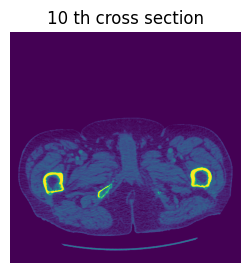

In [2]:
# Volume loading

def load_image(folder):
    files = sorted([
        f for f in os.listdir(folder)
        if f.lower().endswith('.jpg')
    ])
    
    if not files:
        raise ValueError(f"No .jpg file found in : {folder}")
    # print(files)
    slices = []
    for f in files:
        path = os.path.join(folder, f)
        img = np.array(Image.open(path).convert('L'))
        slices.append(img)
    
    return np.stack(slices, axis=0)

repos = sorted([
    d for d in os.listdir("data/images/train")
    if os.path.isdir(os.path.join("data/images/train", d))
])

image_to_use = 3
slice_to_visualize = 10
folder = f"data/images/train/{repos[image_to_use]}"
# print(folder)

volume = load_image(folder)
print('Volume shape: ', np.shape(volume))

# Display image
plt.subplots(1, figsize = (4, 3))
plt.imshow(volume[slice_to_visualize, :, :])
plt.title(f"{slice_to_visualize} th cross section")
plt.axis('off')
plt.show()

# Creating the YOLO data format

In [3]:
def parse_annotations(json_path, output_label_dir, list_classes):
    """
    Convert a single JSON annotation file into per-slice YOLO-format label files.

    The input JSON contains all bounding boxes for an entire CT series.
    This function splits them into one .txt file per slice, which is what
    YOLO expects: each image must have a paired label file with the same stem.

    YOLO bounding box format (already used in the source JSON, no conversion needed):
        <class_id> <center_x> <center_y> <width> <height>
    All values are normalized to [0, 1] relative to image dimensions.

    Args:
        json_path (str): Path to the JSON annotation file for one series.
        output_label_dir (str): Directory where per-slice .txt files will be written.
        list_classes (str): List of classes.
    """
    with open(json_path) as f:
        data = json.load(f)

    os.makedirs(output_label_dir, exist_ok=True)
    series_name = data["quadrigram_nb"]
    slices = data["slices_annotations"]

    for slice_nb, content in slices.items():
        lines = []
        for class_name, bboxes in content["bboxes"].items():
            if class_name not in list_classes:
                continue
            class_id = list_classes[class_name]
            for bbox in bboxes:
                lines.append(f"{class_id} {bbox['center_x']} {bbox['center_y']} {bbox['width']} {bbox['height']}")

        # creating the same file names as the images (_0000, _0001...)
        label_name = f"{series_name}_{int(slice_nb):04d}.txt"
        label_path = os.path.join(output_label_dir, label_name)
        with open(label_path, "w") as f:
            f.write("\n".join(lines))
    return

def build_yolo_dataset(src_images_root, dst_root, global_ID, annotations_path, folder_names, list_classes):
    """
    Reorganise the raw dataset into the flat directory structure expected by Ultralytics YOLO.

    YOLO requires:
        dataset_yolo/
            images/
                train/   ← all training images, flat (no per-series subfolders)
                val/     ← all validation images, flat
            labels/
                train/   ← one .txt per image, same stem as the image
                val/

    The source data has images nested inside per-series subdirectories.
    This function flattens them into a single images/{split}/ folder and
    generates the matching label files via parse_annotations.

    Args:
        src_images_root (str): Root folder containing train/ and val/ subfolders,
                               each with per-series subdirectories of .jpg images.
        dst_root (str): Root of the new YOLO-compatible dataset to create.
        global_ID (list of lists): global_ID[i] is a list of JSON annotation filenames
                                   for split i (e.g. [["series_A.json", ...], ["series_C.json", ...]]).
        annotations_path (str): Root directory where the JSON annotation files live.
        folder_names (list of str): Split names in the same order as global_ID
                                    (e.g. ["train", "val"]).
        list_classes (list of str): Ordered list of class names used to build CLASS_TO_ID
                                    and to verify annotations against the known vocabulary.
    """
    for split in ["train", "val"]:
        dst_img_dir = os.path.join(dst_root, "images", split)
        os.makedirs(dst_img_dir, exist_ok=True)

        # Copy images from raw data to new dataset
        src_img_split = os.path.join(src_images_root, split)
        for entry in os.listdir(src_img_split):
            entry_path = os.path.join(src_img_split, entry)

            if os.path.isdir(entry_path):
                for fname in os.listdir(entry_path):
                    if fname.lower().endswith('.jpg'):
                        shutil.copy2(os.path.join(entry_path, fname),
                                     os.path.join(dst_img_dir, fname))
            elif entry.lower().endswith('.jpg'):
                shutil.copy2(entry_path, os.path.join(dst_img_dir, entry))

        n_imgs = len(os.listdir(dst_img_dir))
        print(f"[{split}] {n_imgs} images copied")

    # Create labels and divide them per series and slice
    os.makedirs(os.path.join(dst_root, "labels"), exist_ok=True)

    for i in range(len(global_ID)):
        label_dir = os.path.join(dst_root, "labels", folder_names[i])
        os.makedirs(label_dir, exist_ok=True)

        for j in range(len(global_ID[i])):
            temp_path = os.path.join(annotations_path, global_ID[i][j])
            parse_annotations(temp_path, label_dir, list_classes)

        n_labels = len(os.listdir(label_dir))
        print(f"[{folder_names[i]}] {n_labels} labels created")
    return

# Classes definition
# Full list of vessel classes to detect, ordered by class ID (index = ID used in YOLO labels).
# The ordering must remain consistent throughout: in the YAML config, in annotation parsing,
# and at inference time — any mismatch will silently misclassify predictions.
CLASSES = [
    "no_name",
    "aorta",
    "ascending_aorta",
    "celiac_trunk",
    "superior_mesenteric",
    "left_renal",
    "right_renal",
    "left_common_iliac",
    "left_external_iliac",
    "left_internal_iliac",
    "right_common_iliac",
    "right_external_iliac",
    "right_internal_iliac",
    "left_subclavian",
    "brachiocephalic_trunk",
    "left_common_carotid",
    "left_external_carotid",
    "left_internal_carotid",
    "right_common_carotid",
    "right_external_carotid",
    "right_internal_carotid"
]

# Maps class name (string) → integer ID for fast lookup during annotation parsing.
# Direction matters: YOLO labels are written as integers, so we need string → int.
# (Inverting to {id: name} would silently produce no annotations.)
CLASS_TO_ID = {name: i for i, name in enumerate(CLASSES)}

# Paths
annotations_path = "data/annotations"

training_ID = [
    "annotations_Anonymized_Database_Patient_127_postop_28_05_2019_aorta.json",
    "annotations_Pellegrin_2020_carotid_Patient_003_preop_05_11_2019_24MUNDKM.json",
    "annotations_Pellegrin_2020_carotid_Patient_030_P5NHAEJZ_20200603_P MOLLES P MOLLES ARTERIEL.json",
    "annotations_USP_exam_992.json"
    ]

validation_ID = [
    "annotations_Pellegrin_2020_carotid_Patient_012_preop_28_11_2019_0LJXTBUV.json",
    "annotations_Pellegrin_2021_PostEvar_study_P007_postop_21_12_2018_Aorte.json"
    ]

# Build YOLO dataset: Separate two folders, one for training and one for validation
global_ID = [
    training_ID, 
    validation_ID
    ]

folder_labels = [
    "train", 
    "val"
    ]

build_yolo_dataset(
    src_images_root = "data/images",
    dst_root = "dataset_yolo",
    global_ID = global_ID,
    annotations_path = annotations_path,
    folder_names = folder_labels,
    list_classes = CLASS_TO_ID
)

[train] 2389 images copied
[val] 1572 images copied
[train] 4778 labels created
[val] 3144 labels created


# Creating the yaml file

In [4]:
# Build the YOLO dataset configuration dictionary.
# 'path' is the absolute root of the dataset; YOLO resolves 'train' and 'val'
# 'names' maps integer IDs to class name strings (used in result plots and logs).
dataset = {
    "path": "dataset_yolo",
    "train": "images/train",
    "val": "images/val",

    "names": {
        0: "no_name",
        1: "aorta",
        2: "ascending_aorta",
        3: "celiac_trunk",
        4: "superior_mesenteric",
        5: "left_renal",
        6: "right_renal",
        7: "left_common_iliac",
        8: "left_external_iliac",
        9: "left_internal_iliac",
        10: "right_common_iliac",
        11: "right_external_iliac",
        12: "right_internal_iliac",
        13: "left_subclavian",
        14: "brachiocephalic_trunk",
        15: "left_common_carotid",
        16: "left_external_carotid",
        17: "left_internal_carotid",
        18: "right_common_carotid",
        19: "right_external_carotid",
        20: "right_internal_carotid"
    }
}

with open("dataset.yaml", "w") as f:
    yaml.dump(dataset, f, default_flow_style=False, sort_keys=False)

print("dataset.yaml created")

dataset.yaml created


# Training and validation

In [5]:
# Load YOLO model
model = YOLO("yolo26s.pt")

model.train(
    data="dataset.yaml",
    epochs=10,
    imgsz=512,
    batch=16, 
    device="mps",
)

/Users/rhembert/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


New https://pypi.org/project/ultralytics/8.4.168 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.65 🚀 Python-3.9.6 torch-2.8.0 MPS (Apple M5)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=dataset.yaml, degrees=0.0, deterministic=True, device=mps, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=512, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-7, nbs=64, nms=False, opset=None, 

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x12532a5e0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.04

  <img src="assets/BoxPR_curve.png" width="45%">
  <img src="assets/confusion_matrix_normalized.png" width="45%">

## Precision-Recall Curve (mAP@0.5 = 0.489)

The Precision-Recall (PR) curve plots, for each class, the trade-off between precision (fraction of predictions that are correct (TP / (TP + FP))) and recall (fraction of ground-truth instances that are found (TP / (TP + FN))) as the confidence threshold is swept from 1 down to 0.

A prediction is counted as a TP only if its bounding box overlaps the ground-truth box with IoU ≥ 0.5; anything below that threshold is a FP, and unmatched ground-truth boxes are FN. A larger area under the curve means better performance at all operating points; mAP@0.5 is the mean of those areas across all 21 classes computed at IoU = 0.5.

**Overall result:** mAP@0.5 = **0.489** (best checkpoint, epoch 8).

**Key observations from the curve:**

- One curve extends to recall ≈ 1.0, which, based on the per-class validation metrics, corresponds to the **aorta** (R = 0.967, AP = 0.97). With 609 training instances, the largest class by a wide margin, the model detects it consistently across the full recall range.

- The **mean curve** (blue, mAP@0.5 = 0.489) starts at a precision around 0.82 at low recall and degrades steadily. This high-precision, low-recall entry point is expected: when the confidence threshold is high, the model only fires on easy, high-confidence detections, but misses many true positives. Lowering the threshold recovers more detections at the cost of precision.

- Several curves cluster near the bottom of the plot (low AP). These correspond to underrepresented classes such as `left_common_iliac` (44 training instances, AP = 0.0918) and `right_renal` (45 instances, AP = 0.466). The model simply has not seen enough examples to reliably locate these structures.

**Takeaway:** The large spread between the best and worst class curves is a direct consequence of class imbalance. Adding more training data for rare classes, or applying class-weighted loss, would be the most impactful next step.

## Confusion Matrix (Normalized)

The confusion matrix shows, for each true class (columns), how the model distributed
its predictions (rows), including a *background* row for missed detections. Values are
normalized column-wise so each column sums to 1: a cell at (predicted Y, true X) reads
"given a ground-truth instance of class X, the model predicted class Y this fraction of
the time." The diagonal gives the per-class recall directly.

**Strong performers — high diagonal values:**

| Class | Diagonal | Interpretation |
|---|---|---|
| `aorta` | 0.97 | Detected in 97% of cases. The most represented class (609 instances), with clear and stable anatomy. |
| `celiac_trunk` | 0.77 | Good detection rate for the amount of instances. |
| `brachiocephalic_trunk` | 0.52 | Reasonable detection, distinctive location in the thorax helps. |
| `right_external_iliac` | 0.49 | Moderate recall despite being one of the better-represented iliac classes. |
| `left_external_carotid` | 0.84 | Great performance with 106 training images. |

**Weak performers — low diagonal, high background row:**

| Class | Diagonal | Background row | Interpretation |
|---|---|---|---|
| `ascendic_aorta` | 0.32 | **0.68** | Low recall despite high precision which means the model is overly conservative, only predicting it when very confident. |
| `left_renal` | 0.00 | **0.96** | Never correctly detected, can be explained by the small size of the vessel and the small amount of data (50). |
| `right_renal` | 0.18 | **0.82** | Rarely detected, same issue with even fewer instances (45). |
| `left_common_iliac` | 0.00 | **0.91** | The weakest class overall, 44 training instances is insufficient. |
| `right_common_iliac` | 0.14 | **0.81** | Rarely detected, same issue with very low amount of data (74). |

**Confusion between similar classes:**

- **`left_external_iliac` predicted as `right_external_iliac`** (0.50): when the true class is
  `left_external_iliac`, the model predicts `right_external_iliac` half of the time. The other way around also happens around 27% of the time.
- **`left_internal_iliac` predicted as `right_internal_iliac`** (0.46): This is an interesting case because despite a similar amount of data the classes only get mixed up in this way and not frequently the other way around (12%).
- **`background` predicted as `no_name`** (0.51): 51% of true background instances get predicted as no_name.
  This makes anatomical sense because no_name is a catch-all label for unlabelled or ambiguous structures.

**Overall pattern:**

The dominant signal is the *background* row at the bottom: for most classes, a good fraction of true instances ends up predicted as background (i.e. simply not detected). This reflects false negatives rather than misclassifications between vessel types, and is a direct consequence of the small training set. The model needs more data more than a different architecture: with more examples, it would learn to fire on the structures it currently skips rather than confusing one vessel for another.

## Example

In [9]:
# # Display some results examples:
# img_pred = Image.open('assets/val_batch0_pred.jpg')
# img_label = Image.open('assets/val_batch0_labels.jpg')

# fig, ax = plt.subplots(1, 2, figsize=(12, 6))

# ax[0].imshow(img_pred)
# ax[0].set_title("Predictions")
# ax[0].axis("off")

# ax[1].imshow(img_label)
# ax[1].set_title("Ground Truth")
# ax[1].axis("off")

# plt.tight_layout()
# plt.show()